# 1. Proje: Veriden Tahmine EV Araç Tercih Analizi
### Uçtan Uca Yapay Zekâ Projesi: Veriden Tahmine

**Hazırlayan:** Büşra  
**Araçlar:** Python, Google Colab, Pandas, NumPy, Matplotlib, scikit-learn

> **Bir cümlede proje:** Bir kişinin yaşı, geliri, günlük yolu ve şarj imkânları gibi bilgilerine bakarak **elektrikli araç (EV) alıp almayacağını** tahmin eden bir yapay zekâ modeli.

Bu defter, eğitimin *Proje Envanteri* belgesindeki **7 aşamayı** sırasıyla takip eder:

| Aşama | Konu | Bu defterdeki çıktı |
|---|---|---|
| 1 | Problem tanımı | Proje Tanım Formu + gerekçe |
| 2 | Veri toplama ve hazırlama | CSV, veri sözlüğü, temizleme |
| 3 | Keşifçi veri analizi (EDA) | Özet tablolar, 4 grafik, keşif bulguları |
| 4 | Model kurma ve eğitme | Karar ağacı modeli, eğitim/test bölünmesi |
| 5 | Tahmin ve değerlendirme | Doğruluk, confusion matrix, 3 yeni örnek |
| 6 | Akıllı tahmin aracı | `tahmin_et()` fonksiyonu ve `input()` uygulaması |
| 7 | Dokümantasyon | Sonuç özeti, sınırlamalar, kaynakça |

**Nasıl çalıştırılır?** Üst menüden **Çalışma zamanı → Tümünü çalıştır** (Runtime → Run all). Ya da her hücreyi seçip **Shift + Enter**. Hücreler yukarıdan aşağı sırayla çalıştırılmalıdır, çünkü her hücre bir öncekinin oluşturduğu değişkenleri kullanır.

**Defter nasıl okunur?** Her kod hücresinin üstünde, o kodun **ne yaptığını** ve **her satırın ne anlama geldiğini** anlatan bir metin hücresi var. Kodun içindeki `#` ile başlayan satırlar da açıklamadır; Python onları çalıştırmaz.

---
# Aşama 1 · Problem Tanımı ve Proje Planı

## Proje Tanım Formu

| Alan | Cevap |
|---|---|
| **Seçilen alan** | Ulaşım / otomotiv |
| **Problem cümlesi** | Bir kişinin *yaş, cinsiyet, gelir, yaşadığı yer, günlük yol, mevcut araç, şarj imkânları, çevre duyarlılığı ve devlet teşviki* bilgilerinden, **elektrikli araç alıp almayacağını** tahmin et. |
| **Hedef değişken (y)** | `Will_Buy_EV` → `Yes` (alır) / `No` (almaz) |
| **Problem türü** | **Sınıflandırma** (çıktı bir sayı değil, iki sınıftan biri) |
| **Kullanılan model** | Karar Ağacı (`DecisionTreeClassifier`) |

### Sınıflandırma mı, regresyon mu?
- **Regresyon**, bir **sayı** tahmin eder. Örnek: “Bu ev kaç TL eder?”, “Bu araba kaç km gider?”
- **Sınıflandırma**, bir **kategori** tahmin eder. Örnek: “Öğrenci geçti mi kaldı mı?”, “Bu kişi EV alır mı almaz mı?”

Bizim cevabımız *Evet* ya da *Hayır* olduğu için problem **sınıflandırmadır**.

## Gerekçe: Bu tahmin neden önemli?
Dünyada otomobil sektörü hızla elektrikli araçlara geçiyor. Ancak birçok insan, devlet teşviklerine ve çevre kaygılarına rağmen **“yolda kalırım” korkusu (menzil kaygısı)** ve şarj imkânı eksikliği yüzünden EV almaktan çekiniyor. EV almaya kimin yatkın olduğunu önceden tahmin etmek birçok kişiye fayda sağlar:
- **Otomobil bayileri** test sürüşü ve kampanyaları doğru müşterilere yönlendirebilir.
- **Belediyeler ve şarj istasyonu şirketleri** yeni istasyonları talebin yüksek olacağı yerlere kurabilir.
- **Kamu kurumları** teşviklerin hangi gruplarda karar değiştirdiğini görebilir.
- **Tüketiciler** kendi durumlarına göre EV'nin onlara uygun olup olmadığını görebilir.

---
# Aşama 2 · Veri Toplama ve Hazırlama

## 2.1 Kütüphaneleri yükleme
**Kütüphane** nedir? Telefona uygulama yüklemek gibi düşün: Python tek başına temel işleri yapar, kütüphaneler ona yeni beceriler kazandırır. Colab'da bu kütüphaneler hazır kurulu gelir, sadece `import` ile çağırırız.

| Satır | Ne yapar? |
|---|---|
| `import pandas as pd` | **Pandas**: Python'un Excel'i. Tabloları okur, filtreler, özetler. `pd` kısa takma adıdır. |
| `import numpy as np` | **NumPy**: Hızlı matematik ve sayı dizileri. |
| `import matplotlib.pyplot as plt` | **Matplotlib**: Grafik çizer. |
| `from sklearn... import ...` | **scikit-learn**: Makine öğrenmesi kütüphanesi. Model, veri bölme ve başarı ölçme araçları buradan gelir. |
| `pd.set_option(...)` | Tabloların ekranda tüm sütunlarıyla görünmesini sağlar. |
| `plt.rcParams[...]` | Tüm grafiklerin varsayılan boyutunu ayarlar. |

In [1]:
# --- Veri işleme ---
import pandas as pd                      # tablolar (DataFrame)
import numpy as np                       # sayısal işlemler

# --- Grafik ---
import matplotlib.pyplot as plt          # grafik çizme

# --- Makine öğrenmesi (scikit-learn) ---
from sklearn.model_selection import train_test_split        # veriyi eğitim/test olarak bölme
from sklearn.tree import DecisionTreeClassifier, plot_tree  # karar ağacı modeli ve çizimi
from sklearn.dummy import DummyClassifier                   # karşılaştırma için "hep aynı cevabı veren" model
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# --- Görünüm ayarları ---
pd.set_option('display.max_columns', None)   # tablolarda tüm sütunları göster
plt.rcParams['figure.figsize'] = (8, 4.5)    # grafiklerin varsayılan boyutu (genişlik, yükseklik)

print('Kütüphaneler yüklendi. pandas', pd.__version__)

Kütüphaneler yüklendi. pandas 2.2.3


## 2.2 Veriyi nasıl buldum?
Probleme uygun bir veri seti bulmak için şu adımları izledim:

1. **Arama:** [Kaggle](https://www.kaggle.com/datasets) sitesinde *“EV adoption”*, *“electric vehicle purchase intention”* ve *“range anxiety”* kelimeleriyle arama yaptım.
2. **Seçim ölçütleri:** (a) Hedef sütunu açıkça *EV alır / almaz* olsun, (b) en az 20 satır ve 2 özellik olsun, (c) lisansı serbest kullanıma izin versin, (d) içinde biraz eksik veri olsun ki temizlemeyi öğrenebileyim.
3. **Bulunan veri:** **EV Adoption Behavior and Range Anxiety** (Kaggle, kullanıcı: *itzzomkar*).
4. **Ek veri:** Aşama 6'da araç önermek için gerçek EV modellerinin teknik özelliklerini içeren **Electric Vehicle Specs Dataset 2025**'i Hugging Face'te buldum.

| | Ana veri (tercih) | Ek veri (araç özellikleri) |
|---|---|---|
| **Kaynak** | [Kaggle · itzzomkar/ev-adoption-behavior-and-range-anxiety](https://www.kaggle.com/datasets/itzzomkar/ev-adoption-behavior-and-range-anxiety) | [Hugging Face · UrvishAhir1/Electric-Vehicle-Specs-Dataset-2025](https://huggingface.co/datasets/UrvishAhir1/Electric-Vehicle-Specs-Dataset-2025) |
| **Boyut** | 10.000 kişi × 15 sütun | 478 araç × 22 sütun |
| **Lisans** | CC0 (kamu malı, serbest) | CC BY 4.0 (kaynak gösterilerek serbest) |
| **Gerçek mi?** | ⚠️ **Sentetik** (bilgisayarla üretilmiş) | Gerçek (kaynağı ev-database.org) |

> ⚠️ **Önemli not:** Ana veri **sentetiktir**, yani gerçek bir anketten değil, gerçekçi dağılımlarla bilgisayarda üretilmiştir. Öğrenmek ve yöntem denemek için çok uygundur, ancak sonuçlar **gerçek tüketici davranışını kanıtlamaz**. Veri setinin yazarı, temizlik pratiği yapılabilsin diye gelir, günlük yol ve çevre duyarlılığı sütunlarına bilerek az sayıda (her birinde yaklaşık %2) eksik değer eklemiştir.

## 2.3 Veriyi indirme
Bu hücre iki veri setini Colab'a indirir ve `dataset/` klasörüne kaydeder.

**Nasıl çalışır?**
- `os.makedirs('dataset', exist_ok=True)` → `dataset` adında bir klasör açar (varsa hata vermez).
- `def hazir(yol)` → küçük bir **fonksiyon**: dosya var mı ve içi dolu mu diye kontrol eder. Böylece hücreyi ikinci kez çalıştırınca tekrar indirmez.
- **Yol 1 – `kagglehub`:** Kaggle'ın resmi Python aracıdır. Veriyi indirip içindeki `.csv` dosyasını bizim klasörümüze kopyalarız.
- **Yol 2 – `curl`:** Yol 1 çalışmazsa Kaggle'ın indirme adresinden ZIP dosyasını doğrudan indirir ve içinden CSV'yi çıkarır.
- **Yol 3 – Elle yükleme:** İkisi de olmazsa bir **Dosya seç** düğmesi çıkar. Kaggle sayfasından indirdiğin dosyayı buradan yüklersin.
- Hugging Face verisi doğrudan `curl` ile indirilir.
- `try / except`: “Bunu dene, hata olursa programı durdurma, şunu yap” demektir.

In [2]:
import os, glob, shutil, subprocess, zipfile

os.makedirs('dataset', exist_ok=True)                 # veri klasörünü oluştur
TERCIH_CSV = 'dataset/ev_adoption.csv'                # ana veri dosyasının yolu
ARAC_CSV   = 'dataset/ev_specs.csv'                   # ek veri dosyasının yolu
KAGGLE_ID  = 'itzzomkar/ev-adoption-behavior-and-range-anxiety'
HF_URL     = ('https://huggingface.co/datasets/UrvishAhir1/Electric-Vehicle-Specs-Dataset-2025'
              '/resolve/main/electric_vehicles_spec_2025.csv')

def hazir(yol, min_bayt=10_000):
    # Dosya var ve en az 10 KB ise True döndürür
    return os.path.exists(yol) and os.path.getsize(yol) > min_bayt

# ---------- Ana veri: Kaggle ----------
if not hazir(TERCIH_CSV):                              # Yol 1: kagglehub
    try:
        import kagglehub
        klasor = kagglehub.dataset_download(KAGGLE_ID)
        csv = glob.glob(f'{klasor}/**/*.csv', recursive=True)[0]
        shutil.copy(csv, TERCIH_CSV)
        print('Kaggle verisi kagglehub ile indirildi.')
    except Exception as hata:
        print('kagglehub çalışmadı:', type(hata).__name__)

if not hazir(TERCIH_CSV):                              # Yol 2: curl ile ZIP
    subprocess.run(['curl', '-sL', '-o', '/tmp/ev.zip',
                    f'https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_ID}'])
    if zipfile.is_zipfile('/tmp/ev.zip'):
        with zipfile.ZipFile('/tmp/ev.zip') as z:
            ad = [n for n in z.namelist() if n.endswith('.csv')][0]
            with z.open(ad) as kaynak, open(TERCIH_CSV, 'wb') as hedef:
                shutil.copyfileobj(kaynak, hedef)
        print('Kaggle verisi curl ile indirildi.')

if not hazir(TERCIH_CSV):                              # Yol 3: elle yükleme
    print('Otomatik indirme olmadı. Şu sayfadan CSV dosyasını indir ve aşağıdan yükle:')
    print('https://www.kaggle.com/datasets/' + KAGGLE_ID)
    from google.colab import files
    yuklenen = list(files.upload())[0]
    shutil.move(yuklenen, TERCIH_CSV)

# ---------- Ek veri: Hugging Face ----------
if not hazir(ARAC_CSV):
    subprocess.run(['curl', '-sL', '-o', ARAC_CSV, HF_URL])

for yol in [TERCIH_CSV, ARAC_CSV]:
    print(f'{yol:28s}', 'HAZIR' if hazir(yol) else 'EKSİK', f'({os.path.getsize(yol):,} bayt)')

dataset/ev_adoption.csv      HAZIR (692,429 bayt)
dataset/ev_specs.csv         HAZIR (86,210 bayt)


## 2.4 CSV dosyasını Pandas ile okuma
**CSV** (Comma-Separated Values), değerleri virgülle ayrılmış düz bir tablo dosyasıdır. Excel'de de açılabilir.

- `pd.read_csv(yol)` → dosyayı okur ve bir **DataFrame**'e çevirir. DataFrame = satır ve sütunlardan oluşan tablo. Değişkenin adı `df` (data frame) olarak kullanılır.
- `df.shape` → (satır sayısı, sütun sayısı).
- `df.head()` → ilk 5 satırı gösterir. Veriye “ilk bakış” için kullanılır.
- `display(...)` → Colab'da tabloyu düzgün görünümle yazdırır.

In [3]:
df = pd.read_csv(TERCIH_CSV)          # ana veri: kişiler
araclar = pd.read_csv(ARAC_CSV)       # ek veri: araç modelleri (Aşama 6'da kullanılacak)

print('Ana veri boyutu  (satır, sütun):', df.shape)
print('Araç verisi boyutu (satır, sütun):', araclar.shape)
display(df.head())

Ana veri boyutu  (satır, sütun): (10000, 15)
Araç verisi boyutu (satır, sütun): (478, 22)


,Buyer_ID,Age,Gender,Annual_Income_USD,City_Type,Daily_Commute_km,Number_of_Cars_Owned,Current_Car_Type,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Home_Charging_Possible,Environmental_Concern_Level,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,EV00001,56,Male,44906.0,Rural,18.1,1,Truck,1,0,Yes,4.0,Yes,Low,No
1,EV00002,36,Male,88754.0,Rural,5.0,1,SUV,2,3,Yes,1.0,Yes,Low,No
2,EV00003,42,Male,155958.0,Urban,32.2,2,Sedan,14,3,No,2.0,Yes,Medium,Yes
3,EV00004,31,Male,37059.0,Rural,89.9,1,Sedan,2,1,Yes,4.0,No,Low,No
4,EV00005,48,Female,48552.0,Rural,71.0,1,Sedan,2,0,Yes,3.0,Yes,Low,No


## 2.5 Veri sözlüğü
**Veri sözlüğü**, her sütunun ne anlama geldiğini açıklayan tablodur. Bir projeyi başkası okuduğunda ilk baktığı yer burasıdır.

Aşağıdaki kod her sütunun **tipini**, **eksik değer sayısını** ve **kaç farklı değer aldığını** otomatik çıkarır:
- `df.dtypes` → sütun tipi. `int64` tam sayı, `float64` ondalıklı sayı, `object` yazı (metin) demektir.
- `df.isnull().sum()` → her sütundaki boş hücre sayısı.
- `df.nunique()` → her sütundaki farklı değer sayısı.

In [4]:
sozluk = pd.DataFrame({
    'tip':           df.dtypes.astype(str),
    'eksik_deger':   df.isnull().sum(),
    'farkli_deger':  df.nunique(),
    'ornek':         df.iloc[0],          # ilk satırdaki değer
})
display(sozluk)

,tip,eksik_deger,farkli_deger,ornek
Buyer_ID,object,0,10000,EV00001
Age,int64,0,45,56
Gender,object,0,3,Male
Annual_Income_USD,float64,178,8915,44906.0
City_Type,object,0,3,Rural
Daily_Commute_km,float64,181,991,18.1
Number_of_Cars_Owned,int64,0,4,1
Current_Car_Type,object,0,4,Truck
Charging_Stations_Near_Home,int64,0,15,1
Charging_Stations_Near_Work,int64,0,20,0


| Sütun | Tür | Anlamı | Rolü |
|---|---|---|---|
| `Buyer_ID` | Kimlik | Her kişinin benzersiz numarası | ❌ Kullanılmaz (bilgi taşımaz) |
| `Age` | Sayısal | Yaş (25–70) | Özellik (X) |
| `Gender` | Kategorik | Cinsiyet: Male / Female / Other | Özellik (X) |
| `Annual_Income_USD` | Sayısal | Yıllık gelir (ABD doları) | Özellik (X) |
| `City_Type` | Kategorik | Yaşadığı yer: Urban (şehir merkezi) / Suburban (banliyö) / Rural (kırsal) | Özellik (X) |
| `Daily_Commute_km` | Sayısal | Günlük gidip gelme mesafesi (km) | Özellik (X) |
| `Number_of_Cars_Owned` | Sayısal | Hanedeki araç sayısı | Özellik (X) |
| `Current_Car_Type` | Kategorik | Şu anki araç tipi: Sedan / SUV / Hatchback / Truck | Özellik (X) |
| `Charging_Stations_Near_Home` | Sayısal | Evin yakınındaki şarj istasyonu sayısı | Özellik (X) |
| `Charging_Stations_Near_Work` | Sayısal | İşin yakınındaki şarj istasyonu sayısı | Özellik (X) |
| `Home_Charging_Possible` | Kategorik | Evde şarj imkânı: Yes / No | Özellik (X) |
| `Environmental_Concern_Level` | Sayısal (1–5) | Çevre duyarlılığı (1 düşük, 5 yüksek) | Özellik (X) |
| `Subsidy_Available` | Kategorik | Devlet teşviki var mı: Yes / No | Özellik (X) |
| `Range_Anxiety_Level` | Kategorik | Menzil kaygısı: Low / Medium / High | ❌ Kullanılmaz (aşağıda açıklandı) |
| **`Will_Buy_EV`** | Kategorik | **EV alacak mı: Yes / No** | 🎯 **Hedef (y)** |

**Neden `Range_Anxiety_Level`'ı kullanmıyoruz?** Menzil kaygısı, kişinin *karar anındaki duygusudur* ve veri setinde ikinci bir hedef olarak verilmiştir. Gerçek hayatta bir bayi, müşteriye “menzil kaygınız ne düzeyde?” diye ölçülmüş bir değer bilemez. Modeli sadece **önceden bilinebilecek** bilgilerle kurmak daha dürüst bir sonuç verir.

## 2.6 Eksik değerleri bulma ve temizleme
**Eksik değer**, anket formunda boş bırakılmış bir soru gibidir. Pandas bunları `NaN` (Not a Number) olarak gösterir. Model boş hücreyle çalışamaz, o yüzden ya **silmek** ya da **doldurmak** gerekir.

**Hangi yöntemi seçtim, neden?**
- Eksikler sadece **sayısal** sütunlarda ve az sayıda. Satırları silseydim, o kişilerin diğer 13 sütundaki bilgisi de kaybolurdu.
- Bu yüzden eksikleri o sütunun **ortanca (median)** değeriyle doldurdum. Ortanca, sayılar küçükten büyüğe dizildiğinde **tam ortadaki** değerdir. Ortalamadan farkı: birkaç çok yüksek gelirli kişi ortalamayı yukarı çeker, ama ortancayı etkilemez.
- Kategorik bir sütunda eksik olsaydı, en sık görülen değerle (mod) doldurulurdu. Kod bunu da kontrol ediyor.

**Kod satır satır:**
- `for sutun in df.columns:` → her sütunu sırayla gez.
- `if df[sutun].isnull().sum() > 0:` → o sütunda eksik varsa…
- `pd.api.types.is_numeric_dtype(df[sutun])` → “Bu sütun sayı mı?” diye sorar. Sayıysa ortanca ile, değilse en sık değerle (`mode()[0]`) doldurur.
- `fillna(...)` → boş hücreleri verilen değerle doldurur.

In [5]:
print('Temizlemeden ÖNCE eksik değerler:')
eksik_once = df.isnull().sum()
print(eksik_once[eksik_once > 0])
print('Toplam eksik hücre:', int(eksik_once.sum()),
      f'(tüm hücrelerin %{eksik_once.sum() / df.size * 100:.2f}’si)')

for sutun in df.columns:
    if df[sutun].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(df[sutun]):
            doldurma = df[sutun].median()           # sayısal → ortanca
        else:
            doldurma = df[sutun].mode()[0]          # kategorik → en sık değer
        df[sutun] = df[sutun].fillna(doldurma)
        print(f'  {sutun}: eksikler {doldurma} ile dolduruldu')

print('\nTemizlemeden SONRA toplam eksik hücre:', int(df.isnull().sum().sum()))
print('Tekrarlanan satır sayısı:', df.duplicated().sum())

Temizlemeden ÖNCE eksik değerler:
Annual_Income_USD              178
Daily_Commute_km               181
Environmental_Concern_Level    184
dtype: int64
Toplam eksik hücre: 543 (tüm hücrelerin %0.36’si)
  Annual_Income_USD: eksikler 84708.0 ile dolduruldu
  Daily_Commute_km: eksikler 40.2 ile dolduruldu
  Environmental_Concern_Level: eksikler 3.0 ile dolduruldu

Temizlemeden SONRA toplam eksik hücre: 0
Tekrarlanan satır sayısı: 0


---
# Aşama 3 · Keşifçi Veri Analizi (EDA) ve Görselleştirme
**EDA** (Exploratory Data Analysis), model kurmadan önce veriyi tanımaktır. Yemeğe başlamadan dolabı açıp ne var ne yok bakmak gibi.

## 3.1 Özet istatistikler
`df.describe()` her sayısal sütun için şunları verir:

| Satır | Anlamı |
|---|---|
| `count` | Dolu hücre sayısı |
| `mean` | Ortalama |
| `std` | Standart sapma: değerlerin ortalamadan ne kadar dağıldığı |
| `min` / `max` | En küçük / en büyük değer |
| `25%`, `50%`, `75%` | Çeyrekler. `50%` ortancadır. |

`.round(1)` sayıları virgülden sonra 1 basamağa yuvarlar.

In [6]:
display(df.describe().round(1))

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
mean,46.9,85366.6,41.1,1.9,5.3,7.5,3.0
std,12.9,32545.2,23.1,0.9,4.0,5.3,1.4
min,25.0,30000.0,5.0,1.0,0.0,0.0,1.0
25%,36.0,61883.5,23.6,1.0,2.0,3.0,2.0
50%,47.0,84708.0,40.2,2.0,5.0,6.0,3.0
75%,58.0,106938.5,56.7,2.0,8.0,11.0,4.0
max,69.0,223345.0,135.5,4.0,14.0,19.0,5.0


## 3.2 Hedef değişkenin dağılımı
`value_counts()` bir sütundaki her değerin kaç kez geçtiğini sayar. `normalize=True` eklenirse sayı yerine **oran** verir.

Bu adım çok önemli: Eğer `Yes` ve `No` sayıları çok farklıysa (**dengesiz sınıflar**), model “hep çoğunluğu söyle” stratejisiyle yüksek doğruluk alabilir ama aslında hiçbir şey öğrenmemiş olur.

,kişi sayısı,yüzde (%)
Will_Buy_EV,,
No,8250,82.5
Yes,1750,17.5


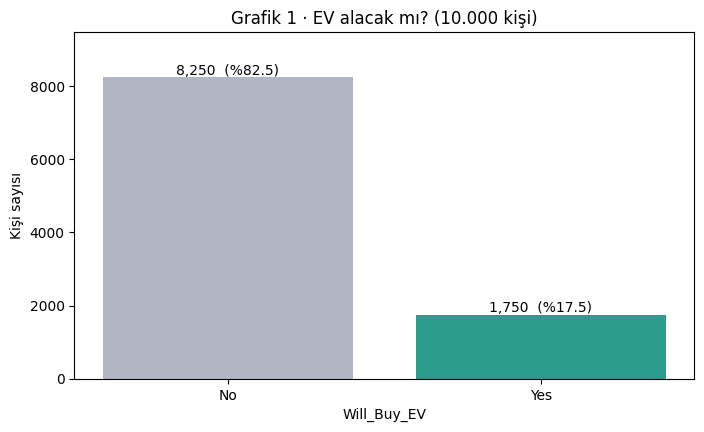

In [7]:
sayi = df['Will_Buy_EV'].value_counts()
oran = df['Will_Buy_EV'].value_counts(normalize=True) * 100
display(pd.DataFrame({'kişi sayısı': sayi, 'yüzde (%)': oran.round(1)}))

# Grafik 1: Hedefin dağılımı (çubuk grafik)
renkler = {'Yes': '#2a9d8f', 'No': '#b0b7c3'}
plt.bar(sayi.index, sayi.values, color=[renkler[k] for k in sayi.index])
for i, v in enumerate(sayi.values):
    plt.text(i, v + 80, f'{v:,}  (%{oran.iloc[i]:.1f})', ha='center')
plt.title('Grafik 1 · EV alacak mı? (10.000 kişi)')
plt.xlabel('Will_Buy_EV')
plt.ylabel('Kişi sayısı')
plt.ylim(0, sayi.max() * 1.15)
plt.show()

## 3.3 Hangi grup daha çok EV alıyor? (`groupby`)
`groupby`, veriyi bir sütuna göre gruplara ayırır ve her grup için hesap yapar. Excel'deki **Özet Tablo (Pivot)** gibi.

Hedefi önce sayıya çeviriyoruz: `Yes → 1`, `No → 0`. Böylece bir grubun **ortalaması**, doğrudan o gruptaki **EV alma oranını** verir. Örneğin 10 kişiden 3'ü Yes ise ortalama 0,3 = %30.

- `df['Will_Buy_EV'].map({'Yes': 1, 'No': 0})` → her Yes'i 1, No'yu 0 yapar.
- `df.groupby(sutun)['ev_alir'].mean()` → her grubun EV alma oranı.
- `sort_values(ascending=False)` → büyükten küçüğe sırala.

In [8]:
df['ev_alir'] = df['Will_Buy_EV'].map({'Yes': 1, 'No': 0})   # analiz için 0/1 sütunu

for sutun in ['Home_Charging_Possible', 'Subsidy_Available', 'City_Type',
              'Current_Car_Type', 'Gender', 'Environmental_Concern_Level']:
    tablo = (df.groupby(sutun)['ev_alir']
               .agg(kisi_sayisi='count', ev_alma_orani='mean')
               .sort_values('ev_alma_orani', ascending=False))
    tablo['ev_alma_orani'] = (tablo['ev_alma_orani'] * 100).round(1)
    print(f'--- {sutun} ---')
    display(tablo)

--- Home_Charging_Possible ---


,kisi_sayisi,ev_alma_orani
Home_Charging_Possible,,
Yes,6163,20.1
No,3837,13.4


--- Subsidy_Available ---


,kisi_sayisi,ev_alma_orani
Subsidy_Available,,
Yes,6008,27.4
No,3992,2.5


--- City_Type ---


,kisi_sayisi,ev_alma_orani
City_Type,,
Rural,1496,19.0
Suburban,3563,17.7
Urban,4941,16.9


... (2 outputs left out)

--- Gender ---


,kisi_sayisi,ev_alma_orani
Gender,,
Female,4498,18.0
Male,5201,17.1
Other,301,16.6


--- Environmental_Concern_Level ---


,kisi_sayisi,ev_alma_orani
Environmental_Concern_Level,,
5.0,1908,41.4
4.0,1989,25.3
3.0,2142,14.8
2.0,1948,4.9
1.0,2013,2.1


## 3.4 Sayısal özelliklerde fark var mı?
Aşağıdaki tablo, EV **alanların** ve **almayanların** sayısal özelliklerdeki **ortalamalarını** yan yana koyar. Büyük fark olan özellik, karar için önemli olabilir.

In [9]:
sayisal = ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned',
           'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level']
display(df.groupby('Will_Buy_EV')[sayisal].mean().round(1).T)

Will_Buy_EV,No,Yes
Age,46.9,47.1
Annual_Income_USD,82769.0,97611.9
Daily_Commute_km,41.4,39.7
Number_of_Cars_Owned,1.9,1.9
Charging_Stations_Near_Home,5.4,5.3
Charging_Stations_Near_Work,7.5,7.5
Environmental_Concern_Level,2.7,4.1


## 3.5 Grafikler
**Grafik 2 – Çubuk grafik:** Evde şarj imkânı ve devlet teşvikinin birlikte etkisi.
**Grafik 3 – Histogram:** Gelirin, EV alanlar ve almayanlar için dağılımı. Histogram, sayıları aralıklara (kutulara) bölüp her aralıkta kaç kişi olduğunu gösterir.
**Grafik 4 – Dağılım (scatter) grafiği:** Gelir ve eve yakın şarj istasyonu sayısı. Her nokta bir kişi; yeşil noktalar EV alanlar.

Her grafiğe `plt.title`, `plt.xlabel`, `plt.ylabel` ile **başlık ve eksen etiketi** ekledik; grafiği yorumlamak için bunlar şarttır.

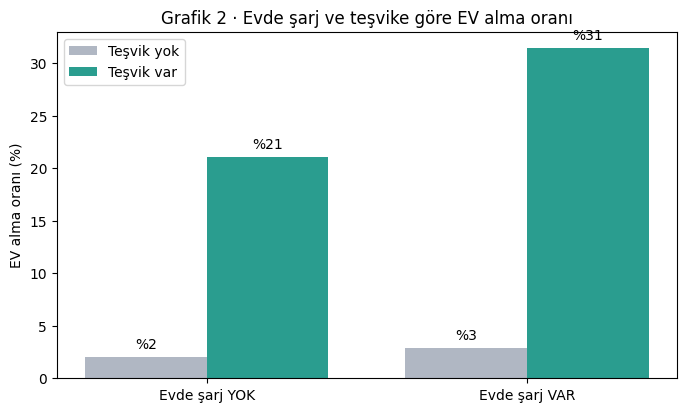

EV alma oranı (%) — satır: evde şarj, sütun: teşvik


Subsidy_Available,No,Yes
Home_Charging_Possible,,
No,2.0,21.0
Yes,2.9,31.4


In [10]:
# Grafik 2: Evde şarj × teşvik → EV alma oranı
pivot = (df.pivot_table(index='Home_Charging_Possible', columns='Subsidy_Available',
                        values='ev_alir', aggfunc='mean') * 100)
x = np.arange(len(pivot.index))
genislik = 0.38
plt.bar(x - genislik/2, pivot['No'],  genislik, label='Teşvik yok', color='#b0b7c3')
plt.bar(x + genislik/2, pivot['Yes'], genislik, label='Teşvik var', color='#2a9d8f')
for i in range(len(x)):
    plt.text(x[i] - genislik/2, pivot['No'].iloc[i] + 0.8,  f"%{pivot['No'].iloc[i]:.0f}", ha='center')
    plt.text(x[i] + genislik/2, pivot['Yes'].iloc[i] + 0.8, f"%{pivot['Yes'].iloc[i]:.0f}", ha='center')
plt.xticks(x, ['Evde şarj YOK' if i == 'No' else 'Evde şarj VAR' for i in pivot.index])
plt.title('Grafik 2 · Evde şarj ve teşvike göre EV alma oranı')
plt.ylabel('EV alma oranı (%)')
plt.legend()
plt.show()

print('EV alma oranı (%) — satır: evde şarj, sütun: teşvik')
display(pivot.round(1))

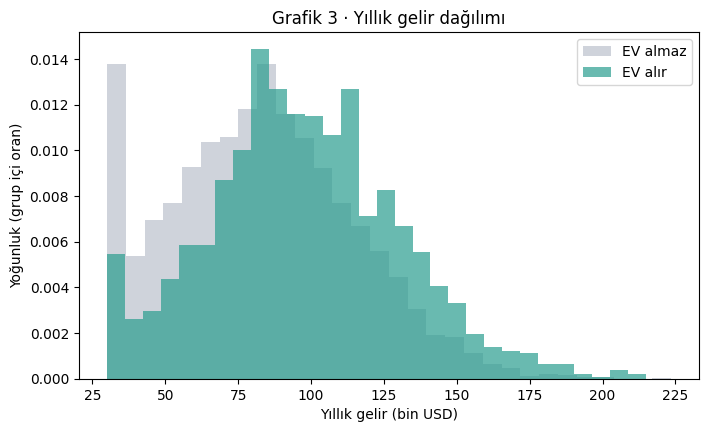

In [11]:
# Grafik 3: Gelir dağılımı (histogram)
alan    = df[df['Will_Buy_EV'] == 'Yes']['Annual_Income_USD'] / 1000
almayan = df[df['Will_Buy_EV'] == 'No']['Annual_Income_USD'] / 1000
plt.hist(almayan, bins=30, alpha=0.6, label='EV almaz', color='#b0b7c3', density=True)
plt.hist(alan,    bins=30, alpha=0.7, label='EV alır',  color='#2a9d8f', density=True)
plt.title('Grafik 3 · Yıllık gelir dağılımı')
plt.xlabel('Yıllık gelir (bin USD)')
plt.ylabel('Yoğunluk (grup içi oran)')
plt.legend()
plt.show()

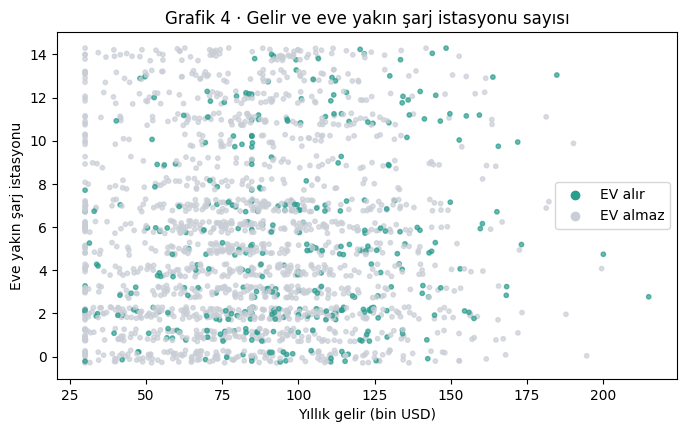

In [12]:
# Grafik 4: Gelir × eve yakın şarj istasyonu (scatter)
ornek = df.sample(2000, random_state=42)              # 10.000 nokta çok kalabalık olur, 2.000 kişi seç
renk = ornek['Will_Buy_EV'].map({'Yes': '#2a9d8f', 'No': '#c9ced6'})
titresim = np.random.default_rng(0).uniform(-0.3, 0.3, len(ornek))   # üst üste binmesin diye küçük kaydırma
plt.scatter(ornek['Annual_Income_USD'] / 1000, ornek['Charging_Stations_Near_Home'] + titresim,
            c=renk, s=10, alpha=0.7)
plt.scatter([], [], c='#2a9d8f', label='EV alır')
plt.scatter([], [], c='#c9ced6', label='EV almaz')
plt.title('Grafik 4 · Gelir ve eve yakın şarj istasyonu sayısı')
plt.xlabel('Yıllık gelir (bin USD)')
plt.ylabel('Eve yakın şarj istasyonu')
plt.legend()
plt.show()

## 3.6 Keşif Bulguları
Yukarıdaki tablolara ve grafiklere bakarak şu sonuçlara vardım:

1. **Sınıflar dengesiz.** 10.000 kişinin sadece **1.750'si (%17,5)** EV alıyor, 8.250'si (%82,5) almıyor. Bu yüzden Aşama 5'te sadece doğruluğa bakmak yanıltıcı olacak.
2. **Devlet teşviki en güçlü etken.** Teşvik **varsa** EV alma oranı **%27,4**, **yoksa** sadece **%2,5**. Yani teşvik, oranı yaklaşık **11 kat** artırıyor.
3. **Çevre duyarlılığı arttıkça EV alma oranı düzenli olarak artıyor.** Duyarlılık 1 olanlarda %2,1, 3 olanlarda %14,8, 5 olanlarda **%41,4**.
4. **Gelir yüksek olanlar daha çok EV alıyor.** EV alanların ortalama yıllık geliri yaklaşık **97.600 USD**, almayanlarınki **82.800 USD**.
5. **Evde şarj tek başına sınırlı etki yapıyor.** Evde şarj imkânı olanlarda oran %20,1, olmayanlarda %13,4. Grafik 2'ye göre teşvik yoksa, evde şarj olsa bile oran %3'ün altında kalıyor. Teşvikle birlikte olunca **%31,4**'e çıkıyor.
6. **Bazı özellikler neredeyse hiç fark yaratmıyor:** yaş (47,1 ve 46,9), günlük yol, şehir tipi (%16,9–%19,0), araç tipi ve cinsiyet. Modelin bunları az kullanmasını bekliyorum.

---
# Aşama 4 · Model Kurma ve Eğitme

## 4.1 Özellikleri (X) ve hedefi (y) ayırma
Makine öğrenmesinde veri ikiye ayrılır:
- **X (özellikler):** Modelin bakacağı bilgiler. “Soru kâğıdı.”
- **y (hedef):** Modelin tahmin etmeyi öğreneceği cevap. “Cevap anahtarı.”

**Kategorik sütunları sayıya çevirme (one-hot encoding):** Model yazı anlamaz, sadece sayı anlar. `pd.get_dummies` her kategori için ayrı bir 0/1 sütunu açar. Örneğin `City_Type` sütunu şuna dönüşür:

| City_Type | → | City_Type_Suburban | City_Type_Urban |
|---|---|---|---|
| Rural | | 0 | 0 |
| Suburban | | 1 | 0 |
| Urban | | 0 | 1 |

`drop_first=True` ilk kategoriyi (burada *Rural*) atar, çünkü diğer ikisi 0 ise zaten *Rural* olduğu anlaşılır. Bu, gereksiz tekrarı önler.

In [13]:
OZELLIKLER = ['Age', 'Gender', 'Annual_Income_USD', 'City_Type', 'Daily_Commute_km',
              'Number_of_Cars_Owned', 'Current_Car_Type', 'Charging_Stations_Near_Home',
              'Charging_Stations_Near_Work', 'Home_Charging_Possible',
              'Environmental_Concern_Level', 'Subsidy_Available']

X = pd.get_dummies(df[OZELLIKLER], drop_first=True, dtype=int)   # yazıları 0/1 sütunlarına çevir
y = df['Will_Buy_EV']                                            # hedef: Yes / No

print('X boyutu:', X.shape, ' → ', X.shape[1], 'sütun')
print('y boyutu:', y.shape)
print('\nModele giren sütunlar:')
print(list(X.columns))

X boyutu: (10000, 16)  →  16 sütun
y boyutu: (10000,)

Modele giren sütunlar:
['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender_Male', 'Gender_Other', 'City_Type_Suburban', 'City_Type_Urban', 'Current_Car_Type_SUV', 'Current_Car_Type_Sedan', 'Current_Car_Type_Truck', 'Home_Charging_Possible_Yes', 'Subsidy_Available_Yes']


## 4.2 Eğitim ve test verisine bölme
Öğrenciye sınavda kitaptaki soruların **aynısını** sorarsan, gerçekten öğrenip öğrenmediğini anlayamazsın. Bu yüzden veriyi ikiye ayırıyoruz:
- **Eğitim verisi (%80):** Model bununla öğrenir.
- **Test verisi (%20):** Model bunu **hiç görmez**. Sonunda başarısını bununla ölçeriz.

`train_test_split` parametreleri:
| Parametre | Anlamı |
|---|---|
| `test_size=0.2` | Verinin %20'si test için ayrılır. |
| `stratify=y` | Yes/No oranı eğitimde ve testte **aynı** kalsın. Dengesiz veride çok önemli. |
| `random_state=42` | Bölme her çalıştırmada aynı olsun, sonuçlar değişmesin. (42 sadece bir sayı, herhangi bir sayı olabilir.) |

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Eğitim X:', X_train.shape, '| Eğitim y:', y_train.shape)
print('Test   X:', X_test.shape,  '| Test   y:', y_test.shape)
print('\nYes oranı → eğitim: %{:.1f} | test: %{:.1f}'.format(
    (y_train == 'Yes').mean() * 100, (y_test == 'Yes').mean() * 100))

Eğitim X: (8000, 16) | Eğitim y: (8000,)
Test   X: (2000, 16) | Test   y: (2000,)

Yes oranı → eğitim: %17.5 | test: %17.5


## 4.3 Model seçimi ve gerekçesi
**Seçilen model: Karar Ağacı (`DecisionTreeClassifier`)**

Karar ağacı, bir **akış şeması** gibi çalışır: “Evde şarj var mı? → Evet → Geliri 60 binin üstünde mi? → …” şeklinde sorular sorarak sonuca varır.

**Neden bu model?**
1. Problemimiz **sınıflandırma** (Yes/No). `LinearRegression` sayı tahmin ettiği için uygun değil.
2. Karar ağacı **açıklanabilir**: Hangi soruları sorduğunu çizip görebiliriz. Yeni başlayan biri için modelin “nasıl düşündüğünü” anlamak çok değerli.
3. Hem sayısal hem 0/1 sütunlarla, ölçeklendirme gerekmeden çalışır.

**Ayarlar (hiperparametreler):**
| Ayar | Anlamı |
|---|---|
| `max_depth=5` | Ağaç en fazla 5 soru derinliğinde olsun. Sınırsız ağaç eğitim verisini **ezberler** (aşırı öğrenme). |
| `min_samples_leaf=20` | Her yaprakta en az 20 kişi olsun; tek tük kişilere özel kurallar oluşmasın. |
| `class_weight='balanced'` | Az olan **Yes** sınıfına daha çok önem ver. Yoksa model hep “No” deme eğiliminde olur. |
| `random_state=42` | Sonuç her seferinde aynı çıksın. |

`model.fit(X_train, y_train)` → **eğitim** komutudur: “Bu soruları ve cevaplarını çalış.”

In [15]:
model = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                               class_weight='balanced', random_state=42)
model.fit(X_train, y_train)          # modeli eğitim verisiyle eğit
print('Model eğitildi.')
print('Ağacın derinliği:', model.get_depth(), '| yaprak sayısı:', model.get_n_leaves())

Model eğitildi.
Ağacın derinliği: 5 | yaprak sayısı: 31


## 4.4 Ağacın ilk kararlarını görelim
`plot_tree` eğitilen ağacı çizer. Okunabilir olsun diye sadece ilk 2 seviyeyi gösteriyoruz (`max_depth=2`). Her kutuda:
- En üstte **sorulan soru** (örn. `Home_Charging_Possible_Yes <= 0.5` → “Evde şarj YOK mu?”),
- `samples`: o kutuya düşen kişi sayısı,
- `class`: o kutudaki tahmin.

Sol ok “evet (koşul doğru)”, sağ ok “hayır” demektir.

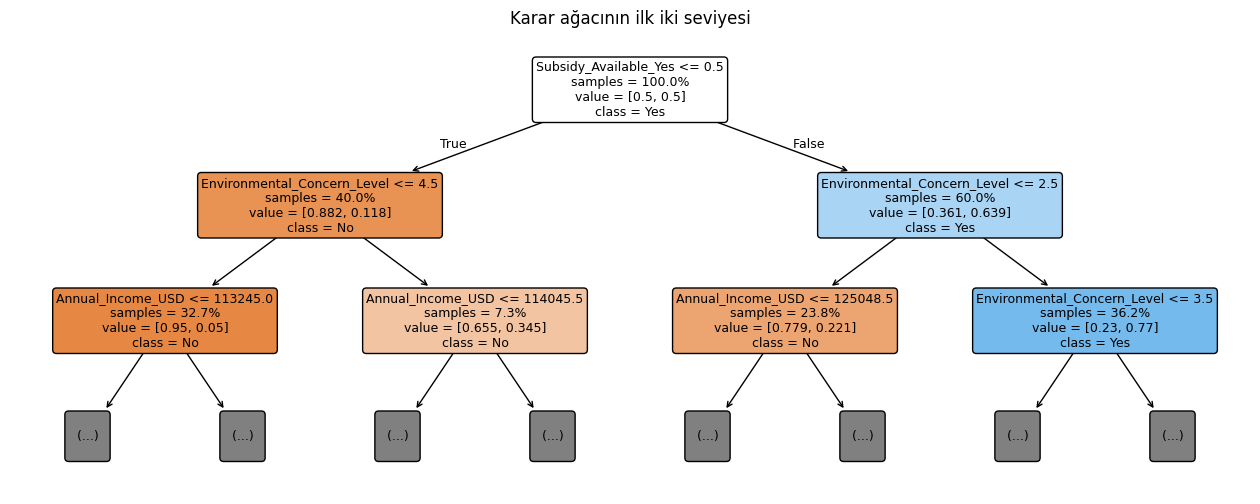

In [16]:
plt.figure(figsize=(16, 6))
plot_tree(model, max_depth=2, feature_names=X.columns, class_names=model.classes_,
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title('Karar ağacının ilk iki seviyesi')
plt.show()

---
# Aşama 5 · Tahmin ve Değerlendirme

## 5.1 Test verisinde tahmin ve doğruluk
- `model.predict(X_test)` → model, hiç görmediği test kişileri için Yes/No tahmin eder.
- `accuracy_score(gerçek, tahmin)` → tahminlerin yüzde kaçı doğru?

**Temel çizgi (baseline):** Hiçbir şey öğrenmeden **hep “No” diyen** bir model düşünelim (`DummyClassifier`). Veride çoğunluk No olduğu için bu “aptal” model bile yüksek doğruluk alır. Gerçek modelimizin değeri, bu temel çizgiden **ne kadar iyi** olduğuyla ölçülür.

In [17]:
tahmin = model.predict(X_test)
dogruluk = accuracy_score(y_test, tahmin)

temel = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
temel_dogruluk = accuracy_score(y_test, temel.predict(X_test))

print(f'Karar ağacı doğruluğu        : %{dogruluk * 100:.1f}')
print(f'Temel çizgi (hep "No" diyen) : %{temel_dogruluk * 100:.1f}')

Karar ağacı doğruluğu        : %79.0
Temel çizgi (hep "No" diyen) : %82.5


## 5.2 Doğruluk yetmez: Precision, Recall, F1
Dengesiz veride doğruluk tek başına yanıltıcıdır. Bu yüzden **sınıflandırma raporuna** bakarız. **Yes** satırına odaklan:

| Ölçü | Soru | Örnek yorum |
|---|---|---|
| **Precision (kesinlik)** | Model “Yes” dediklerinin kaçı gerçekten Yes? | Bayi, modelin önerdiği 10 kişiden kaçına boşuna gitti? |
| **Recall (duyarlılık)** | Gerçekten Yes olanların kaçını model yakaladı? | EV alacak 10 kişiden kaçını kaçırmadık? |
| **F1** | Precision ile Recall'un dengeli ortalaması | Tek sayıda ikisinin özeti |
| **support** | O sınıfta testte kaç kişi var | |

In [18]:
print(classification_report(y_test, tahmin, digits=3))

              precision    recall  f1-score   support

          No      0.965     0.775     0.859      1650
         Yes      0.449     0.866     0.591       350

    accuracy                          0.790      2000
   macro avg      0.707     0.820     0.725      2000
weighted avg      0.874     0.790     0.812      2000



## 5.3 Confusion matrix (karışıklık matrisi)
Modelin **nerede doğru, nerede yanlış** yaptığını gösteren 2×2 tablodur.
- **Satırlar:** gerçek durum · **Sütunlar:** modelin tahmini
- Sol üst ve sağ alt (köşegen) → **doğru** tahminler
- Diğer iki kutu → **hatalar**:
  - Gerçek *No*, tahmin *Yes* → **yanlış alarm** (bayi boşuna arar)
  - Gerçek *Yes*, tahmin *No* → **kaçırılan müşteri**

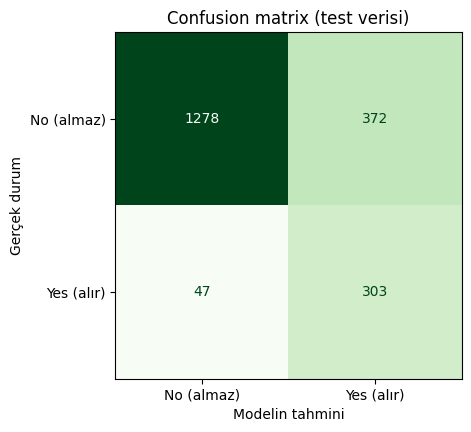

Doğru "No"  (TN): 1278   | Yanlış alarm   (FP): 372
Kaçırılan   (FN): 47   | Doğru "Yes"   (TP): 303


In [19]:
cm = confusion_matrix(y_test, tahmin, labels=['No', 'Yes'])
ConfusionMatrixDisplay(cm, display_labels=['No (almaz)', 'Yes (alır)']).plot(cmap='Greens', colorbar=False)
plt.title('Confusion matrix (test verisi)')
plt.xlabel('Modelin tahmini')
plt.ylabel('Gerçek durum')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Doğru "No"  (TN): {tn}   | Yanlış alarm   (FP): {fp}')
print(f'Kaçırılan   (FN): {fn}   | Doğru "Yes"   (TP): {tp}')

## 5.4 Aşırı öğrenme (overfitting) kontrolü
**Aşırı öğrenme**, öğrencinin konuyu anlamak yerine kitaptaki soruları **ezberlemesi** gibidir: eğitim verisinde çok başarılı olur, yeni sorularda çuvallar.

Kontrol yöntemi: Eğitim skoru ile test skorunu karşılaştır. Aradaki fark küçükse (birkaç puan) model genelleme yapabiliyor demektir.

Karşılaştırma için bir de **sınırsız derinlikte** ağaç eğitiyoruz; ezberin nasıl göründüğünü görmek için.

In [20]:
egitim_skor = model.score(X_train, y_train)
test_skor   = model.score(X_test, y_test)
print(f'Bizim model (max_depth=5) → eğitim: %{egitim_skor*100:.1f} | test: %{test_skor*100:.1f} | fark: {abs(egitim_skor-test_skor)*100:.1f} puan')

ezberci = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)   # derinlik sınırı yok
print(f'Sınırsız ağaç             → eğitim: %{ezberci.score(X_train, y_train)*100:.1f} | test: %{ezberci.score(X_test, y_test)*100:.1f} | derinlik: {ezberci.get_depth()}')

Bizim model (max_depth=5) → eğitim: %79.1 | test: %79.0 | fark: 0.0 puan
Sınırsız ağaç             → eğitim: %100.0 | test: %81.0 | derinlik: 26


## 5.5 Hangi özellikler önemli?
`model.feature_importances_` her sütunun, ağacın kararlarına **ne kadar katkı yaptığını** gösterir. Toplamları 1'dir (yani %100).

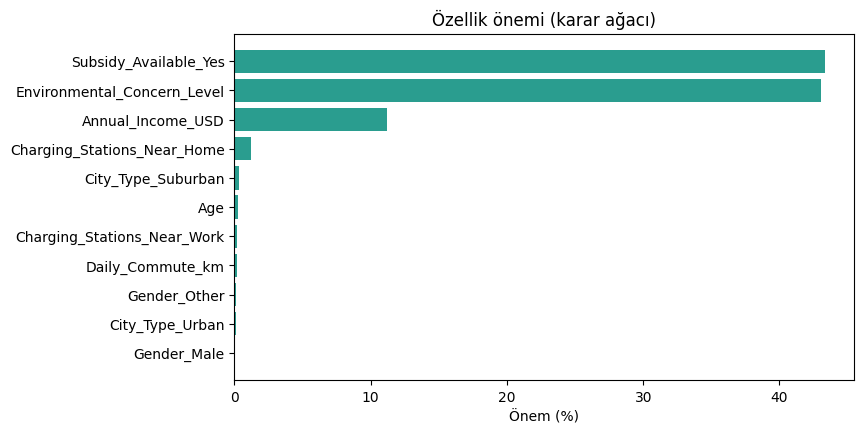

,önem (%)
Subsidy_Available_Yes,43.3
Environmental_Concern_Level,43.1
Annual_Income_USD,11.2
Charging_Stations_Near_Home,1.2
City_Type_Suburban,0.3
Age,0.2
Charging_Stations_Near_Work,0.2
Daily_Commute_km,0.2
Gender_Other,0.1
City_Type_Urban,0.1


In [21]:
onem = pd.Series(model.feature_importances_, index=X.columns).sort_values()
onem = onem[onem > 0]                       # hiç kullanılmayanları gösterme
plt.barh(onem.index, onem.values * 100, color='#2a9d8f')
plt.title('Özellik önemi (karar ağacı)')
plt.xlabel('Önem (%)')
plt.show()
display((onem.sort_values(ascending=False) * 100).round(1).to_frame('önem (%)'))

## 5.6 Üç yeni örnek için tahmin
Modeli hiç olmayan, bizim uydurduğumuz üç kişiyle deniyoruz.

**Önemli teknik detay:** Yeni kişileri de `get_dummies` ile 0/1'e çeviriyoruz. Ama üç kişide bazı kategoriler hiç geçmeyebilir (örneğin hiç *Truck* yoksa o sütun oluşmaz). `reindex(columns=X.columns, fill_value=0)` sütunları eğitimdekiyle **birebir aynı sıraya** dizer ve eksik olanları 0 ile doldurur.

`predict_proba` → her sınıf için **olasılık** verir. Bize `Yes` olasılığı lazım.

In [22]:
yeni_kisiler = pd.DataFrame([
    # Kişi A: şehirde yaşıyor, evde şarj var, teşvik var, çevreye duyarlı
    dict(Age=32, Gender='Female', Annual_Income_USD=85000, City_Type='Urban', Daily_Commute_km=25,
         Number_of_Cars_Owned=1, Current_Car_Type='Hatchback', Charging_Stations_Near_Home=4,
         Charging_Stations_Near_Work=3, Home_Charging_Possible='Yes',
         Environmental_Concern_Level=5, Subsidy_Available='Yes'),
    # Kişi B: kırsalda, evde şarj yok, çevre duyarlılığı düşük
    dict(Age=55, Gender='Male', Annual_Income_USD=40000, City_Type='Rural', Daily_Commute_km=60,
         Number_of_Cars_Owned=2, Current_Car_Type='Truck', Charging_Stations_Near_Home=0,
         Charging_Stations_Near_Work=0, Home_Charging_Possible='No',
         Environmental_Concern_Level=2, Subsidy_Available='No'),
    # Kişi C: banliyö, evde şarj var ama teşvik yok, orta gelir
    dict(Age=41, Gender='Female', Annual_Income_USD=60000, City_Type='Suburban', Daily_Commute_km=35,
         Number_of_Cars_Owned=1, Current_Car_Type='SUV', Charging_Stations_Near_Home=2,
         Charging_Stations_Near_Work=1, Home_Charging_Possible='Yes',
         Environmental_Concern_Level=3, Subsidy_Available='No'),
], index=['Kişi A', 'Kişi B', 'Kişi C'])

X_yeni = pd.get_dummies(yeni_kisiler, drop_first=True, dtype=int).reindex(columns=X.columns, fill_value=0)
yes_sutunu = list(model.classes_).index('Yes')

sonuc = yeni_kisiler[['Age', 'City_Type', 'Annual_Income_USD', 'Home_Charging_Possible',
                      'Subsidy_Available', 'Environmental_Concern_Level']].copy()
sonuc['Tahmin'] = model.predict(X_yeni)
sonuc['EV alma olasılığı (%)'] = (model.predict_proba(X_yeni)[:, yes_sutunu] * 100).round(0)
display(sonuc)

,Age,City_Type,Annual_Income_USD,Home_Charging_Possible,Subsidy_Available,Environmental_Concern_Level,Tahmin,EV alma olasılığı (%)
Kişi A,32,Urban,85000,Yes,Yes,5,Yes,92.0
Kişi B,55,Rural,40000,No,No,2,No,1.0
Kişi C,41,Suburban,60000,Yes,No,3,No,1.0


## 5.7 Değerlendirme Notu
**Model güvenilir mi?** Kısmen. Ne yaptığını iyi bildiği bir alan var, zayıf olduğu bir alan da var.

**Güçlü yönler**
- **EV alacak kişileri kaçırmıyor.** Recall (Yes) = **0,866**, yani gerçekten EV alan 350 kişinin **303'ünü** buldu, sadece 47'sini kaçırdı.
- **Ezber yok.** Eğitim doğruluğu %79,1, test doğruluğu %79,0. Aradaki fark neredeyse sıfır. Derinlik sınırı olmayan ağaç ise eğitimde %100 alıp ezber yaptı (26 seviye derinlik).
- **Kararları anlamlı.** En önemli özellikler **teşvik (%43)**, **çevre duyarlılığı (%43)** ve **gelir (%11)**. Bu, Aşama 3'teki keşif bulgularıyla birebir örtüşüyor.

**Zayıf yönler**
- **Doğruluk, temel çizginin altında: %79,0'a karşı %82,5.** Bunun sebebi bilinçli bir tercih: `class_weight='balanced'` ayarı modele “EV alacak kişiyi kaçırma” dedi. Model bu yüzden daha sık “Yes” diyor ve **372 yanlış alarm** veriyor. Hep “No” diyen model ise %82,5 doğruluk alıyor ama **hiçbir EV alıcısını bulamıyor** (recall = 0). Bir bayi için kaçırılan müşteri, boşuna yapılan bir telefondan daha pahalıdır.
- **Precision (Yes) = 0,449.** Model “alır” dediğinde yarıdan az ihtimalle haklı. Bu yüzden sonuç kesin bir karar olarak değil, “ilgilenmeye değer müşteri listesi” olarak kullanılmalı.
- **Yeni örneklerde aşırı keskin olasılıklar** çıkıyor (%92 ve %1 gibi). Bunun nedeni, karar ağacının kişileri birkaç kutuya ayırması ve her kutuya tek bir olasılık vermesidir.

**Olası iyileştirmeler:** Random Forest gibi daha güçlü bir modeli denemek, `max_depth` ile farklı derinlikler denemek ve gerçek anket verisiyle modeli yeniden eğitmek.

---
# Aşama 6 · Akıllı Tahmin Aracı (Mini Uygulama)

## 6.1 `tahmin_et()` fonksiyonu
**Fonksiyon**, bir yemek tarifi gibidir: malzemeleri verirsin (kişinin bilgileri), tarif adımları uygulanır (model çalışır), yemek çıkar (anlaşılır bir cümle).

- `def tahmin_et(...)` → fonksiyonu tanımlar. Parantez içindekiler **parametre** (malzeme).
- `kisi = dict(...)` → bilgileri bir sözlükte toplar.
- Sonra 5.6'daki gibi 0/1'e çevirir, sütunları hizalar ve olasılığı hesaplar.
- `return` → sonucu fonksiyonun dışına verir.
- **f-string:** `f'... %{olasilik:.0f} ...'` → süslü parantez içindeki değişkeni cümlenin içine yerleştirir. `:.0f` “virgülden sonra 0 basamak” demektir.

Fonksiyon olasılığa göre üç seviyeli bir yorum da üretir: %65 ve üstü *yüksek*, %40–65 *kararsız*, altı *düşük*.

In [23]:
def tahmin_et(yas, cinsiyet, gelir_usd, yasadigi_yer, gunluk_km, arac_sayisi, arac_tipi,
              ev_yakini_istasyon, is_yakini_istasyon, evde_sarj, cevre_duyarliligi, tesvik):
    kisi = dict(Age=yas, Gender=cinsiyet, Annual_Income_USD=gelir_usd, City_Type=yasadigi_yer,
                Daily_Commute_km=gunluk_km, Number_of_Cars_Owned=arac_sayisi,
                Current_Car_Type=arac_tipi, Charging_Stations_Near_Home=ev_yakini_istasyon,
                Charging_Stations_Near_Work=is_yakini_istasyon, Home_Charging_Possible=evde_sarj,
                Environmental_Concern_Level=cevre_duyarliligi, Subsidy_Available=tesvik)
    x = pd.get_dummies(pd.DataFrame([kisi]), drop_first=True, dtype=int).reindex(columns=X.columns, fill_value=0)
    olasilik = model.predict_proba(x)[0][list(model.classes_).index('Yes')] * 100

    if olasilik >= 65:
        yorum = 'Elektrikli araç almaya YÜKSEK ihtimalle yatkın. ✅'
    elif olasilik >= 40:
        yorum = 'KARARSIZ görünüyor; teşvik veya şarj imkânı kararı değiştirebilir. 🤔'
    else:
        yorum = 'Elektrikli araç alma ihtimali DÜŞÜK. ❌'
    return olasilik, yorum

# Deneme: fonksiyonu iki farklı kişiyle doğrudan çağır
for bilgiler in [(30, 'Female', 95000, 'Urban', 20, 1, 'Sedan', 3, 2, 'Yes', 5, 'Yes'),
                 (45, 'Male',   60000, 'Rural', 50, 2, 'SUV',   0, 1, 'No',  2, 'No')]:
    p, yorum = tahmin_et(*bilgiler)
    print(f'Gelir {bilgiler[2]:,} USD, çevre duyarlılığı {bilgiler[10]}, teşvik {bilgiler[11]} → EV alma olasılığı: %{p:.0f} → {yorum}')

Gelir 95,000 USD, çevre duyarlılığı 5, teşvik Yes → EV alma olasılığı: %44 → KARARSIZ görünüyor; teşvik veya şarj imkânı kararı değiştirebilir. 🤔
Gelir 60,000 USD, çevre duyarlılığı 2, teşvik No → EV alma olasılığı: %1 → Elektrikli araç alma ihtimali DÜŞÜK. ❌


## 6.2 Kullanıcıdan bilgi alan uygulama (`input`)
`input('soru')` → ekranda bir kutu açar, kullanıcının yazdığını **metin** olarak döndürür. Sayıya çevirmek için `float(...)` (ondalıklı sayı) kullanılır.

**Kullanıcı dostu küçük dokunuşlar:**
- Sorular Türkçe, cevaplar kısa harflerle: `e/h`, `m/b/k` gibi. Kod bunları modelin anladığı İngilizce değerlere çevirir (`{'e': 'Yes', 'h': 'No'}`).
- `.strip().lower()` → baştaki/sondaki boşlukları siler ve küçük harfe çevirir; “ E ” yazsan da “e” olarak anlar.
- `secim_sor(...)` → kısa harfli cevabı sözlükte arar; sözlükte olmayan bir şey yazılırsa varsayılan değeri kullanır, program çökmez.
- `sayi_sor(...)` → sayı ister. Harf ya da sınır dışı bir değer yazarsan `try / except` hatayı yakalar ve soruyu tekrar sorar.
- `while True:` → doğru cevap gelene kadar sorudan çıkmayan bir döngü.
- Gelir TL olarak sorulur ve `KUR` ile dolara çevrilir, çünkü model ABD doları ile eğitildi. Verideki gelirler yılda 30.000–223.000 USD arasında. Girdiğin gelir bunun altında kalırsa kod seni uyarır.

▶️ **Bu hücreyi çalıştır ve soruları cevapla.** Her cevaptan sonra Enter'a bas.

In [24]:
KUR = 34.0   # 1 USD kaç TL? Çalıştırmadan önce güncel kuru buraya yaz.

def sayi_sor(soru, en_az, en_cok):
    # Kullanıcı yanlış bir şey yazarsa (harf, sınır dışı sayı) program çökmesin, tekrar sorsun
    while True:
        cevap = input(soru).strip().replace(',', '.')
        try:
            deger = float(cevap)
            if en_az <= deger <= en_cok:
                return deger
        except ValueError:
            pass
        print(f'  Lütfen {en_az} ile {en_cok} arasında bir sayı yaz.')

def secim_sor(soru, secenekler, varsayilan):
    # Kısa harfli cevabı (e/h gibi) modelin anladığı değere çevirir
    return secenekler.get(input(soru).strip().lower(), varsayilan)

print('=== EV Tercih Tahmin Aracı ===')
isim       = input('Adın: ').strip() or 'Kullanıcı'
yas        = sayi_sor('Yaşın (25-70): ', 18, 90)
cinsiyet   = secim_sor('Cinsiyet (k=kadın, e=erkek, d=diğer): ', {'k': 'Female', 'e': 'Male'}, 'Other')
gelir_tl   = sayi_sor('Aylık gelirin (TL): ', 0, 10_000_000)
yer        = secim_sor('Yaşadığın yer (m=şehir merkezi, b=banliyö, k=kırsal): ', {'m': 'Urban', 'b': 'Suburban', 'k': 'Rural'}, 'Urban')
gunluk_km  = sayi_sor('Günlük ortalama yolun (km): ', 0, 500)
arac_sayi  = sayi_sor('Evdeki araç sayısı: ', 0, 10)
arac_tipi  = secim_sor('Şu anki araç tipi (s=sedan, u=SUV, h=hatchback, t=kamyonet): ', {'s': 'Sedan', 'u': 'SUV', 'h': 'Hatchback', 't': 'Truck'}, 'Sedan')
ev_ist     = sayi_sor('Evinin yakınındaki şarj istasyonu sayısı: ', 0, 50)
is_ist     = sayi_sor('İşinin yakınındaki şarj istasyonu sayısı: ', 0, 50)
evde_sarj  = secim_sor('Evde şarj edebilir misin? (e/h): ', {'e': 'Yes', 'h': 'No'}, 'No')
cevre      = sayi_sor('Çevre duyarlılığın (1-5): ', 1, 5)
tesvik     = secim_sor('Devlet teşviki var mı? (e/h): ', {'e': 'Yes', 'h': 'No'}, 'No')

gelir_usd_yillik = gelir_tl * 12 / KUR       # aylık TL → yıllık USD
p, yorum = tahmin_et(yas, cinsiyet, gelir_usd_yillik, yer, gunluk_km, arac_sayi, arac_tipi,
                     ev_ist, is_ist, evde_sarj, cevre, tesvik)

print(f'\nMerhaba {isim}! Verdiğin bilgilere göre elektrikli araç alma olasılığın %{p:.0f}.')
print(yorum)
if gelir_usd_yillik < df['Annual_Income_USD'].min():
    print(f'Not: Yıllık gelirin yaklaşık {gelir_usd_yillik:,.0f} USD. Bu, verideki en düşük gelirin '
          f'({df["Annual_Income_USD"].min():,.0f} USD) altında; model bu aralığı hiç görmediği için sonuç güvenilir değil.')

=== EV Tercih Tahmin Aracı ===
Adın: Büşra
Yaşın (25-70): otuz
  Lütfen 18 ile 90 arasında bir sayı yaz.
Yaşın (25-70): 30
Cinsiyet (k=kadın, e=erkek, d=diğer): k
Aylık gelirin (TL): 300000
Yaşadığın yer (m=şehir merkezi, b=banliyö, k=kırsal): m
Günlük ortalama yolun (km): 30
Evdeki araç sayısı: 1
Şu anki araç tipi (s=sedan, u=SUV, h=hatchback, t=kamyonet): h
Evinin yakınındaki şarj istasyonu sayısı: 6
İşinin yakınındaki şarj istasyonu sayısı: 8
Evde şarj edebilir misin? (e/h): e
Çevre duyarlılığın (1-5): 5
Devlet teşviki var mı? (e/h): e

Merhaba Büşra! Verdiğin bilgilere göre elektrikli araç alma olasılığın %44.
KARARSIZ görünüyor; teşvik veya şarj imkânı kararı değiştirebilir. 🤔


## 6.3 Bonus: Sana uygun gerçek elektrikli araçlar
Model “EV alır” derse, bir sonraki soru şudur: **Hangi aracı?** Burada ikinci veri setini (478 gerçek EV modeli) kullanıyoruz.

**Basit kural:** Evde şarj imkânı varsa araç **3 günde bir**, yoksa **haftada bir** şarj edilecek kadar menzile sahip olmalı. En az 250 km olsun.
- `gerekli_menzil = max(gunluk_km * gun, 250)` → gereken en düşük menzil.
- `araclar[araclar['range_km'] >= gerekli_menzil]` → bu menzili karşılayan araçları **filtreler**.
- `sort_values('efficiency_wh_per_km')` → en **az enerji harcayan** (en verimli) araçlar önce gelsin.

Bu fikri daha önce yaptığım bir EV tercih çalışmasından aldım ve yeni başlayanlar için sadeleştirdim.

Günde 40 km, evde şarj VAR → en az 250 km menzil gerekli. En verimli 5 araç:


,Marka,Model,Menzil (km),Batarya (kWh),Tüketim (Wh/km),Kasa
0,Tesla,Model 3 RWD (Highland CATL LFP64),445,60.5,116,Sedan
1,Tesla,Model 3 Long Range RWD (Highland),545,75.0,117,Sedan
2,Hyundai,IONIQ 6 Standard Range 2WD,335,50.0,117,Sedan
3,Tesla,Model 3 Long Range AWD (Highland),525,75.0,119,Sedan
4,Citroen,e-C4 X 54 kWh,335,50.8,119,Sedan



Araç verisinde menzil: en düşük 135 km, ortanca 398 km, en yüksek 685 km


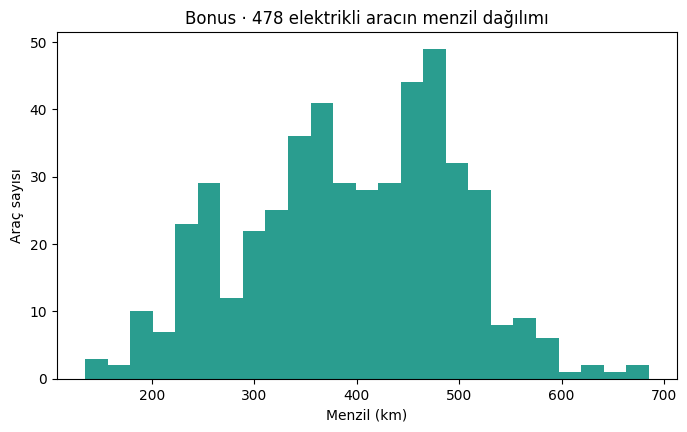

In [25]:
def arac_oner(gunluk_km, evde_sarj, adet=5):
    gun = 3 if evde_sarj == 'Yes' else 7
    gerekli_menzil = max(gunluk_km * gun, 250)
    uygun = araclar[araclar['range_km'] >= gerekli_menzil].sort_values('efficiency_wh_per_km')
    tablo = uygun[['brand', 'model', 'range_km', 'battery_capacity_kWh', 'efficiency_wh_per_km', 'car_body_type']].head(adet)
    tablo.columns = ['Marka', 'Model', 'Menzil (km)', 'Batarya (kWh)', 'Tüketim (Wh/km)', 'Kasa']
    return gerekli_menzil, tablo.reset_index(drop=True)

gerekli, oneriler = arac_oner(gunluk_km=40, evde_sarj='Yes')
print(f'Günde 40 km, evde şarj VAR → en az {gerekli:.0f} km menzil gerekli. En verimli 5 araç:')
display(oneriler)

print(f'\nAraç verisinde menzil: en düşük {araclar.range_km.min()} km, ortanca {araclar.range_km.median():.0f} km, en yüksek {araclar.range_km.max()} km')
plt.hist(araclar['range_km'], bins=25, color='#2a9d8f')
plt.title('Bonus · 478 elektrikli aracın menzil dağılımı')
plt.xlabel('Menzil (km)')
plt.ylabel('Araç sayısı')
plt.show()

---
# Aşama 7 · Dokümantasyon
## Sonuç özeti
| | |
|---|---|
| **Problem** | Bir kişinin bilgilerinden EV alıp almayacağını tahmin etmek (sınıflandırma) |
| **Veri** | Kaggle, 10.000 kişi × 15 sütun (sentetik). 543 eksik hücre ortanca ile dolduruldu. |
| **Model** | Karar ağacı (`max_depth=5`, `class_weight='balanced'`) |
| **Sonuç** | Test doğruluğu **%79,0**. EV alıcılarının **%86,6'sını** buldu (recall). Ezber yok (eğitim ile test arasında fark yok). |
| **En önemli etkenler** | Devlet teşviki, çevre duyarlılığı, gelir |
| **Çıkarım** | Teşvik ve çevre bilinci olmadan EV alma oranı çok düşük kalıyor. Bu veride, EV'yi yaygınlaştırmak için en etkili kaldıraç **teşvik**. |

**Mini uygulama notu:** Aşama 6'daki örnek çalıştırmada aylık 300.000 TL gelir girildi (yaklaşık 105.900 USD/yıl) ve model %44 ile “kararsız” dedi. Aylık 45.000 TL gibi bir gelir girildiğinde ise yıllık gelir yaklaşık 15.900 USD olur. Bu, verideki en düşük gelirin (30.000 USD) bile altındadır ve model çok düşük bir olasılık verir. Uygulama bu durumda kullanıcıyı uyarır. Bu, aşağıdaki 2. sınırlamanın canlı bir örneğidir.

## Sınırlamalar
1. **Veri sentetiktir.** Bilgisayarla üretilmiş 10.000 kişilik bir veri. Yöntemi öğrenmek için ideal, ama sonuçlar gerçek tüketici davranışını kanıtlamaz.
2. **Türkiye'ye genellenemez.** Gelir ABD doları; şehir tipi ve teşvik yapısı Türkiye'den farklı olabilir. TL dönüşümü sadece uygulamayı kullanışlı yapmak içindir.
3. **Fiyat bilgisi yok.** EV kararında araç fiyatı çok önemlidir ama veri setinde yok.
4. **Tek model denendi.** Envanter tek model istiyor; ileride Random Forest veya Logistic Regression ile karşılaştırma yapılabilir.

## Olası iyileştirmeler
- Türkiye'den gerçek anket verisi toplamak (Google Forms ile 50–100 kişi).
- Araç fiyatı, şarj süresi ve elektrik fiyatı gibi sütunlar eklemek.
- Daha güçlü modelleri (Random Forest) denemek ve karşılaştırmak.

## Kaynakça
1. itzzomkar. *EV Adoption Behavior and Range Anxiety* [Veri seti]. Kaggle. Lisans: CC0. https://www.kaggle.com/datasets/itzzomkar/ev-adoption-behavior-and-range-anxiety
2. Ahir, U. *Electric Vehicle Specs Dataset 2025* [Veri seti]. Hugging Face. Lisans: CC BY 4.0. Orijinal kaynak: EV Database (ev-database.org). https://huggingface.co/datasets/UrvishAhir1/Electric-Vehicle-Specs-Dataset-2025
3. Pedregosa, F. ve ark. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. https://scikit-learn.org
4. scikit-learn Kullanıcı Kılavuzu: Karar Ağaçları. https://scikit-learn.org/stable/modules/tree.html
5. pandas Dokümantasyonu. https://pandas.pydata.org/docs/
6. Matplotlib Dokümantasyonu. https://matplotlib.org/stable/
7. Soyak, T. *Uçtan Uca Yapay Zekâ Projesi: Veriden Tahmine – Proje Envanteri* (2026). Eğitim belgesi.
8. Önceki çalışma: *BÜŞRA - 1. Project: EV (Electric Vehicle) preference analysis* (Colab defteri, araç öneri fikri buradan alındı).